# Lab 03 bổ sung — Phân vùng ảnh bằng K-means

**Mục tiêu:** nhóm pixel theo màu RGB. Mỗi pixel là một mẫu với ba đặc trưng R, G, B; không có nhãn vật thể. Notebook dùng `src/model.py` của dự án và lưu kết quả tại `additional_image/results/`.

## Bước 1. Đọc và hiểu ảnh

**Input:** ảnh gốc trong `data/raw/`. Pillow đọc ảnh và chuyển RGB (đỏ, lục, lam), ba kênh có giá trị 0–255. Hình hiển thị và kích thước là đầu ra. **Kiểm tra:** mảng ảnh có ba kênh. Ảnh minh họa Grace Hopper được sao chép từ dữ liệu mẫu đi kèm Matplotlib.

Ảnh gốc: rộng × cao = (512, 600)


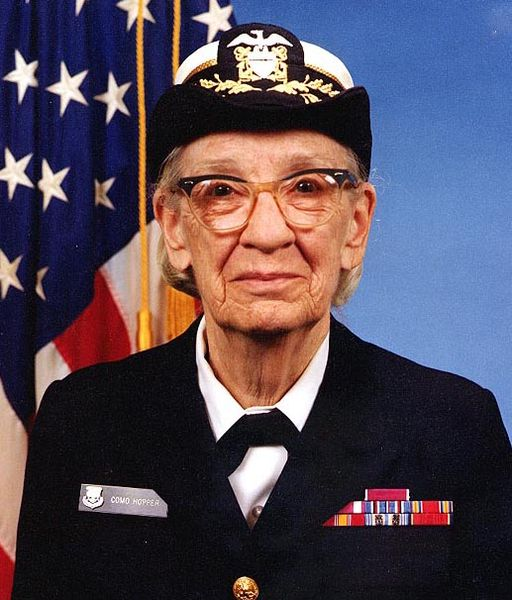

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
while not (root / 'additional_image' / 'config.yaml').exists():
    if root == root.parent:
        raise FileNotFoundError('Không tìm thấy thư mục dự án LA03.')
    root = root.parent
sys.path.insert(0, str(root))
import numpy as np
from PIL import Image
from IPython.display import display, Image as DisplayImage
from additional_image.src.image_processing import load_config, load_image, prepare_image, segment_image
from additional_image.src.visualize import plot_comparison
base = root / 'additional_image'
config = load_config(base / 'config.yaml')
original = load_image(base / config['image_path'])
print('Ảnh gốc: rộng × cao =', original.size)
assert np.asarray(original).shape == (original.height, original.width, 3)
display(original)

## Bước 2. Thu nhỏ và tạo đặc trưng

**Mục đích:** giảm số pixel cần huấn luyện. Ảnh được thu nhỏ giữ tỷ lệ với cạnh lớn nhất theo cấu hình. Mỗi pixel có ba đặc trưng RGB, `reshape(-1, 3)` chuyển ảnh từ cao × rộng × 3 thành số pixel × 3. Không dùng ID hay vị trí pixel làm đặc trưng. **Kiểm tra:** số dòng bằng chiều cao nhân chiều rộng; các giá trị nằm trong 0–255.

Ảnh huấn luyện (rộng × cao): (102, 120)
Ma trận pixel: (12240, 3)


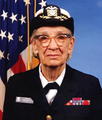

In [2]:
small, train_pixels = prepare_image(original, config['train_max_side'])
assert train_pixels.shape == (small.width * small.height, 3)
assert train_pixels.min() >= 0 and train_pixels.max() <= 255
print('Ảnh huấn luyện (rộng × cao):', small.size)
print('Ma trận pixel:', train_pixels.shape)
display(small)

## Bước 3. Huấn luyện K-means và dựng ảnh

**Cách hoạt động:** `fit()` khởi tạo K tâm RGB, gán mỗi pixel tới tâm có bình phương khoảng cách `Σ(xⱼ − μₖⱼ)²` nhỏ nhất, rồi cập nhật tâm bằng trung bình màu của các pixel trong cụm. Lặp đến ngưỡng dừng hoặc giới hạn vòng. Thử K=3, 5, 8 theo `config.yaml`. **Output:** tâm màu, inertia trên ảnh thu nhỏ và ảnh sau phân cụm. Sau fit, `predict()` gán pixel của ảnh gốc theo từng lô để tiết kiệm bộ nhớ; ảnh kết quả giữ độ phân giải gốc. Tâm màu được làm tròn về số nguyên 0–255.

**Kiểm tra:** số nhãn bằng số pixel ảnh gốc, giá trị nằm trong khoảng RGB, ảnh có tối đa K màu và đúng kích thước. Inertia được tính trên cùng ảnh nhỏ với các K; nó thường giảm khi K tăng, không phải thước đo ý nghĩa vật thể.

In [3]:
results = {}
metrics = []
output = base / 'results'
output.mkdir(exist_ok=True)
for k in config['cluster_counts']:
    model, labels, segmented = segment_image(original, train_pixels, k, config)
    assert segmented.shape == (original.height, original.width, 3)
    assert len(labels) == original.width * original.height
    assert segmented.dtype == np.uint8
    unique_colors = len(np.unique(segmented.reshape(-1, 3), axis=0))
    assert unique_colors <= k
    Image.fromarray(segmented).save(output / f'segmented_k{k}.png')
    results[k] = segmented
    metrics.append({'k': k, 'inertia_train': model.inertia_, 'iterations': model.n_iter_, 'converged': bool(model.converged_), 'unique_output_colors': unique_colors, 'centers_rgb': model.cluster_centers_.tolist()})
    print(f'K={k}: inertia={model.inertia_:.2f}, vòng={model.n_iter_}, hội tụ={model.converged_}, màu đầu ra={unique_colors}')
(output / 'metrics.json').write_text(json.dumps({'config': config, 'original_size': list(original.size), 'train_size': list(small.size), 'results': metrics}, ensure_ascii=False, indent=2), encoding='utf-8')

K=3: inertia=32929658.63, vòng=28, hội tụ=True, màu đầu ra=3
K=5: inertia=14300443.05, vòng=21, hội tụ=True, màu đầu ra=5
K=8: inertia=7898478.59, vòng=26, hội tụ=True, màu đầu ra=8
Out[0]: 2651


## Bước 4. Trực quan hóa và đọc kết quả

Ảnh gốc và ba ảnh kết quả đặt cạnh nhau. K nhỏ gộp nhiều màu và làm mất chi tiết màu; K lớn hơn có thêm màu đại diện. Đây là phân cụm theo màu, các vật thể khác nhau có màu giống nhau vẫn có thể chung nhóm. Đề yêu cầu quan sát ảnh; không dùng Silhouette để khẳng định chất lượng nhận diện vật thể. Mở `results/` để xem từng ảnh PNG.

Đã lưu ảnh so sánh, ảnh từng K và metrics.json.


Fallback to a different backend


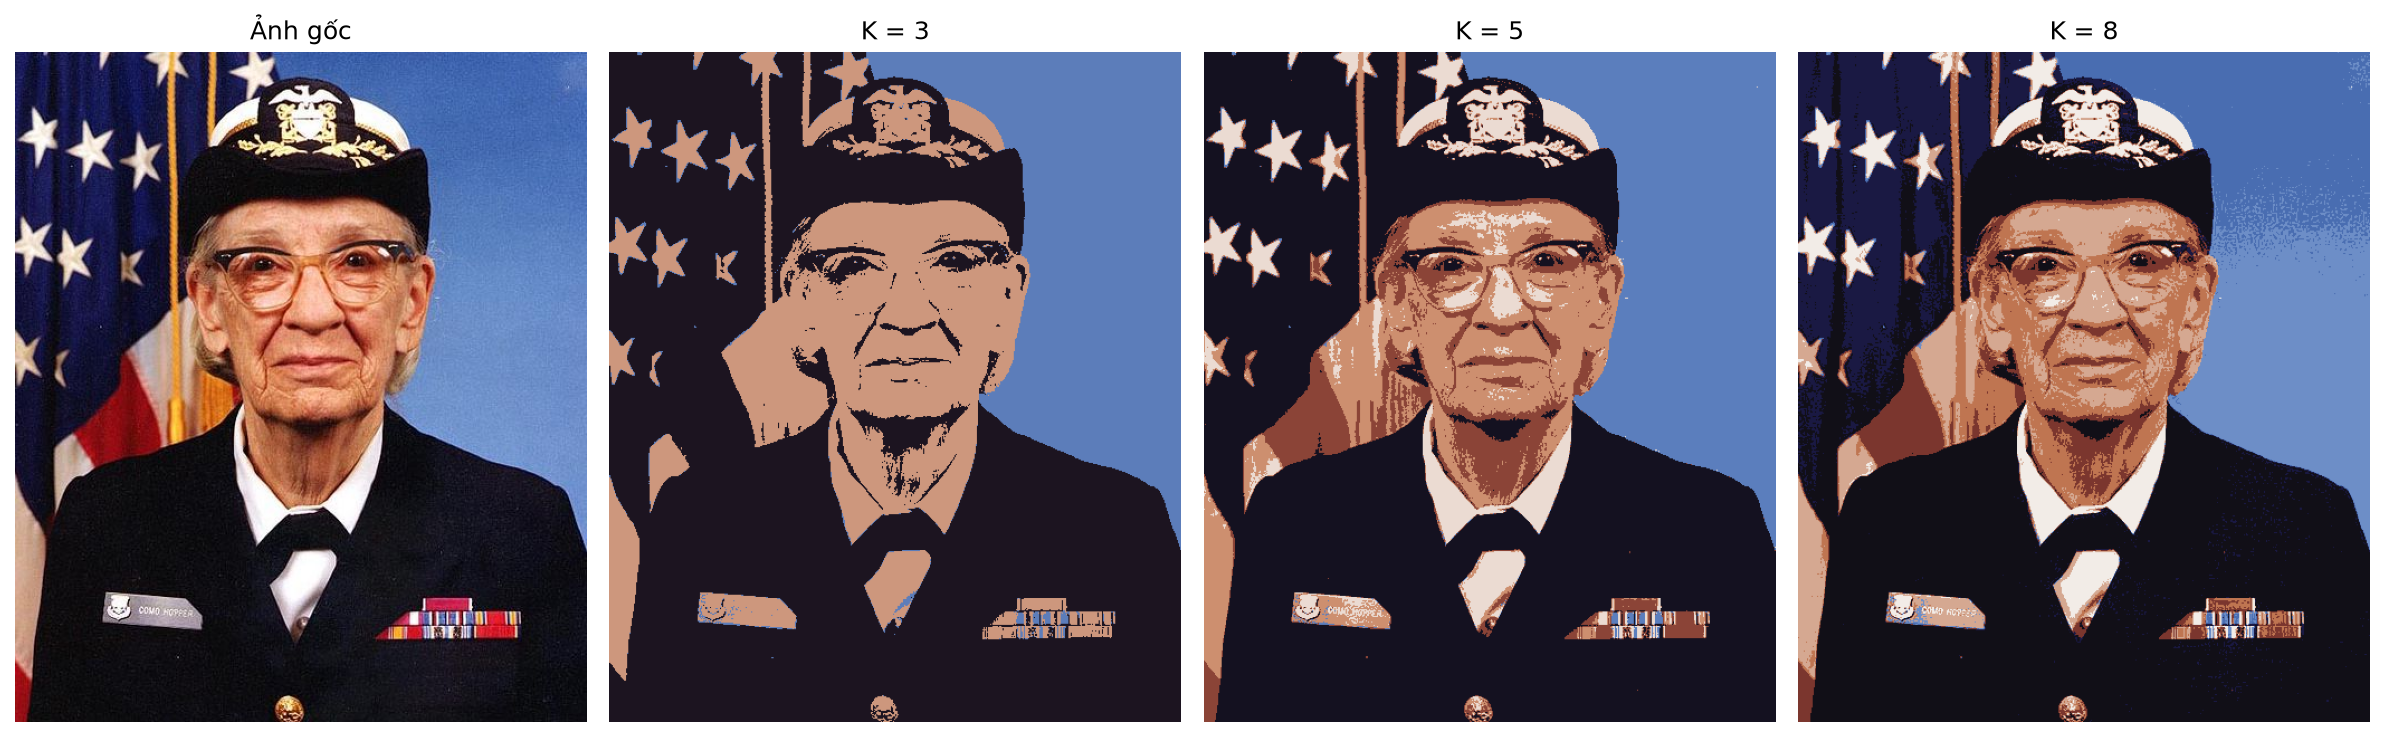

In [4]:
plot_comparison(original, results, output / 'comparison.png')
display(DisplayImage(filename=str(output / 'comparison.png')))
print('Đã lưu ảnh so sánh, ảnh từng K và metrics.json.')